In [ ]:
!pip install langchain-openai
!pip install langgraph
!pip install pymongo
!pip install matplotlib
!pip install dnspython
!pip install seaborn

In [ ]:
from pymongo import MongoClient
from pymongo.errors import ConnectionFailure

# Defina a string de conexão e o nome do banco de dados
CONNECTION_STRING = "mongodb+srv:/"
DATABASE_NAME = "ecommerce"

def test_mongodb_connection():
    """Testa a conexão com o MongoDB e lista informações básicas."""
    try:
        # Conectar ao MongoDB
        client = MongoClient(CONNECTION_STRING, serverSelectionTimeoutMS=5000)
        # Tentar obter informações do servidor
        server_info = client.server_info()
        print("Conexão com o MongoDB estabelecida com sucesso.")
        print(f"Versão do servidor: {server_info['version']}")
        
        # Listar bancos de dados disponíveis
        print("\nBancos de dados disponíveis:")
        print(client.list_database_names())
        
        # Acessar o banco de dados específico
        db = client[DATABASE_NAME]
        
        # Listar coleções no banco de dados
        print(f"\nColeções no banco de dados '{DATABASE_NAME}':")
        collections = db.list_collection_names()
        print(collections)
        
        # Contar documentos em cada coleção
        for collection_name in collections:
            collection = db[collection_name]
            count = collection.count_documents({})
            print(f"Coleção '{collection_name}' tem {count} documentos.")
        
        # Fechar a conexão
        client.close()
        
    except ConnectionFailure as e:
        print("Falha ao conectar-se ao MongoDB:")
        print(e)
    except Exception as e:
        print("Erro ao testar a conexão com o MongoDB:")
        print(e)

# Executar o teste
test_mongodb_connection()

Conexão com o MongoDB estabelecida com sucesso.
Versão do servidor: 8.0.39-patch-a3d00565977

Bancos de dados disponíveis:
['ecommerce', 'sample_mflix', 'admin', 'local']

Coleções no banco de dados 'ecommerce':
['clientes', 'pedidos', 'produtos']
Coleção 'clientes' tem 1300 documentos.
Coleção 'pedidos' tem 1600 documentos.
Coleção 'produtos' tem 850 documentos.


In [ ]:
# Importações necessárias
import warnings
warnings.filterwarnings('ignore')

import os
import io
import base64
import json
import re
import matplotlib.pyplot as plt
import seaborn as sns  # Importar seaborn para gráficos avançados
from IPython.display import display, HTML
from typing_extensions import TypedDict
from typing import List, Dict, Any, Annotated

# Importações do LangGraph e LangChain
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, END, START
from langgraph.checkpoint.memory import MemorySaver
from langchain_core.messages import SystemMessage, HumanMessage

# Importações do MongoDB
from pymongo import MongoClient
from pymongo.errors import ConnectionFailure

# Importação de segurança para avaliação segura de expressões
import ast

# Configuração do ambiente (defina sua chave de API da OpenAI)
os.environ['OPENAI_API_KEY'] = 'sk-proj'  # Substitua pela sua chave de API

# Definir o modelo de linguagem
model = ChatOpenAI(model_name="gpt-4o-mini", temperature=0)

# Definir o estado do agente usando TypedDict
class AgentState(TypedDict):
    question: str
    database_info: str
    database: str
    query: str
    reflect: Annotated[List[str], "add"]
    accepted: bool
    revision: int
    max_revision: int
    results: List[Dict[str, Any]]
    interpretation: str
    plot_needed: bool
    plot_type: str  # Novo campo para o tipo de gráfico
    plot_html: str
    error: str

# Configuração da conexão com o MongoDB
CONNECTION_STRING = "mongodb+srv://"
DATABASE_NAME = "ecommerce"

# Função para verificar a conexão com o MongoDB
def check_mongodb_connection():
    """Verifica se a conexão com o MongoDB está estabelecida corretamente."""
    try:
        client = MongoClient(CONNECTION_STRING, serverSelectionTimeoutMS=3000)
        client.admin.command('ping')
        client.close()
        print("Conexão com o MongoDB estabelecida com sucesso.")
    except ConnectionFailure:
        print("Falha ao conectar-se ao MongoDB. Verifique se o serviço está em execução e as credenciais estão corretas.")

# Chamar a função de verificação de conexão
check_mongodb_connection()

# Função para obter informações do banco de dados
def get_database_info():
    """Obtém informações sobre as coleções e campos disponíveis no banco de dados."""
    client = MongoClient(CONNECTION_STRING)
    db = client[DATABASE_NAME]
    
    info = "Coleções disponíveis:\n"
    
    # Listar coleções e seus campos
    for collection_name in db.list_collection_names():
        info += f"\nColeção: {collection_name}\n"
        # Pegar um documento de exemplo para ver os campos
        sample = db[collection_name].find_one()
        if sample:
            info += "Campos:\n"
            for field in sample.keys():
                if field != "_id":  # Ignorar o campo _id
                    info += f" - {field}\n"
    
    client.close()
    return info

# Definir os nós para o LangGraph

def search_engineer_node(state: AgentState):
    """Obtém informações sobre o banco de dados e atualiza o estado."""
    state['database_info'] = get_database_info()
    state['database'] = DATABASE_NAME
    return state

def query_writer_node(state: AgentState):
    """Gera a query MongoDB em formato de dicionário Python, incluindo o nome da coleção."""
    role_prompt = """
Você é um especialista em MongoDB e PyMongo. Sua tarefa é escrever uma query MongoDB em formato de dicionário Python que responda à pergunta do usuário.

A query deve:
- Usar a sintaxe de dicionário do Python compatível com PyMongo.
- Incluir o nome da coleção a ser consultada, usando a chave 'collection'.
- Utilizar os nomes das coleções e campos conforme definidos no banco de dados.
- Retornar apenas o dicionário Python que representa a query, sem cercas de código ou texto adicional.
- Não incluir cercas de código, anotações de linguagem (como ```python) ou qualquer texto extra.

Por exemplo, para contar o número de produtos em cada categoria na coleção 'produtos', a query seria:

{
    'collection': 'produtos',
    'aggregate': [
        {
            '$group': {
                '_id': '$categoria',
                'total_produtos': { '$sum': 1 }
            }
        }
    ]
}
"""

    instruction = f"Informações do banco de dados:\n{state['database_info']}\n"
    if len(state['reflect']) > 0:
        instruction += f"Considere os seguintes feedbacks:\n{chr(10).join(state['reflect'])}\n"
    instruction += f"Escreva a query MongoDB em formato de dicionário Python que responda à seguinte pergunta: {state['question']}\n"

    messages = [
        SystemMessage(content=role_prompt),
        HumanMessage(content=instruction)
    ]

    response = model.invoke(messages)
    state['query'] = response.content.strip()
    state['revision'] += 1
    return state

def qa_engineer_node(state: AgentState):
    """Verifica se a query MongoDB está correta."""
    role_prompt = """
Você é um engenheiro de QA especializado em MongoDB. Sua tarefa é verificar se a query fornecida responde corretamente à pergunta do usuário.
"""

    instruction = f"Com base nas seguintes informações do banco de dados:\n{state['database_info']}\n"
    instruction += f"E na seguinte query MongoDB:\n{state['query']}\n"
    instruction += f"Verifique se a query pode completar a tarefa: {state['question']}\n"
    instruction += "Responda 'ACEITO' se estiver correta ou 'REJEITADO' se não estiver.\n"

    messages = [
        SystemMessage(content=role_prompt),
        HumanMessage(content=instruction)
    ]

    response = model.invoke(messages)
    state['accepted'] = 'ACEITO' in response.content.upper()
    return state

def chief_dba_node(state: AgentState):
    """Fornece feedback para melhorar a query MongoDB."""
    role_prompt = """
Você é um DBA experiente, especialista em MongoDB. Sua tarefa é fornecer feedback detalhado para melhorar a query fornecida.
"""

    instruction = f"Com base nas seguintes informações do banco de dados:\n{state['database_info']}\n"
    instruction += f"E na seguinte query MongoDB:\n{state['query']}\n"
    instruction += f"Por favor, forneça recomendações para melhorar a query para a tarefa: {state['question']}\n"

    messages = [
        SystemMessage(content=role_prompt),
        HumanMessage(content=instruction)
    ]

    response = model.invoke(messages)
    state['reflect'].append(response.content)
    return state

def execute_query_node(state: AgentState):
    """Executa a query MongoDB usando PyMongo."""
    client = MongoClient(CONNECTION_STRING)
    db = client[state['database']]

    try:
        # Limpar a query removendo cercas de código e texto adicional
        query_str = state['query'].strip()

        # Remover cercas de código usando expressões regulares
        query_str = re.sub(r'^```.*?$', '', query_str, flags=re.MULTILINE)
        query_str = query_str.strip('`').strip()

        # Avaliar o dicionário da query de forma segura
        query_dict = ast.literal_eval(query_str)

        # Obter a coleção a ser consultada
        if isinstance(query_dict, dict):
            collection_name = query_dict.get('collection')
            if not collection_name:
                raise ValueError("A query deve especificar a coleção no formato {'collection': 'nome_da_colecao', ...}")
            collection = db[collection_name]

            # Obter filtros e outras informações
            query_filter = query_dict.get('filter', {})
            query_projection = query_dict.get('projection')
            query_aggregate = query_dict.get('aggregate')

            # Executar a query de acordo com o tipo
            if query_aggregate:
                # Operação de agregação
                pipeline = query_aggregate
                cursor = collection.aggregate(pipeline)
            else:
                # Consulta padrão find()
                cursor = collection.find(query_filter, query_projection)

            # Obter os resultados
            state['results'] = list(cursor)
        else:
            raise ValueError("Formato de query não suportado.")

        # Serializar os resultados para JSON
        state['results'] = json.loads(json.dumps(state['results'], default=str))

        # Adicionar informações de debug
        print(f"Query executada com sucesso. Resultados: {len(state['results'])} documentos.")

    except Exception as e:
        print(f"Erro na execução da query: {str(e)}")
        state['results'] = []
        state['error'] = str(e)
    finally:
        client.close()

    return state

def interpret_results_node(state: AgentState):
    """Interpreta os resultados da query e sugere se um gráfico é necessário."""
    role_prompt = """
Você é um assistente especializado em interpretar resultados de queries MongoDB e explicá-los em linguagem natural.
Sua tarefa é:
- Analisar os resultados da query e fornecer uma resposta clara e concisa à pergunta original do usuário.
- Se houver dados numéricos ,categorias para comparar, precos, quantidade, e etc, sugira um tipo de gráfico adequado (por exemplo, gráfico de barras, gráfico de pizza, gráfico de dispersão, boxplot, violin plot, etc.).
- Seja criterioso na sugestão de gráficos e sugira apenas quando for relevante. Apenas comente sobre a sugestão de gráfico se o grafico tiver sido feito, caso contrario, nao comente sobre a sugestão de grafico.
- Retorne sua resposta no seguinte formato:

Interpretação: <sua interpretação aqui>
Sugestão de gráfico: <tipo de gráfico sugerido ou 'Nenhum' se não for aplicável>
"""

    instruction = f"Pergunta original: {state['question']}\n"
    instruction += f"Resultados da query: {state['results']}\n"
    if state.get('error'):
        instruction += f"Erro encontrado: {state['error']}\n"
    instruction += "Por favor, interprete esses resultados e sugira um tipo de gráfico se aplicável e feito, seguindo as instruções acima. Caso o grafico nao tenha sido feito, nao comente sobre a sugestão de grafico."

    messages = [
        SystemMessage(content=role_prompt),
        HumanMessage(content=instruction)
    ]

    response = model.invoke(messages)
    response_content = response.content.strip()

    # Processar a resposta para extrair interpretação e sugestão de gráfico
    interpretation = ''
    plot_suggestion = ''
    lines = response_content.split('\n')
    for line in lines:
        if line.startswith('Interpretação:'):
            interpretation = line[len('Interpretação:'):].strip()
        elif line.startswith('Sugestão de gráfico:'):
            plot_suggestion = line[len('Sugestão de gráfico:'):].strip()

    state['interpretation'] = interpretation
    plot_suggestion_lower = plot_suggestion.lower()
    if plot_suggestion_lower != 'nenhum':
        state['plot_needed'] = True
        state['plot_type'] = plot_suggestion_lower
    else:
        state['plot_needed'] = False
        state['plot_type'] = ''
    return state

import io
import base64
import math
import matplotlib.pyplot as plt

from collections import Counter


def plot_categorias(state: AgentState) -> AgentState:
    state["plot_html"] = ""
    results = state.get("results") or []

    if not results or not all(isinstance(r, dict) for r in results):
        print("Sem dados para gerar o gráfico.")
        return state

    if any("categoria" in r for r in results):
        counts = Counter(
            str(r.get("categoria") or "Sem categoria")
            for r in results
        )
        items = list(counts.items())
        metric = "Quantidade de registros"

    elif all("_id" in r for r in results):
        numeric_keys = [
            k for k, v in results[0].items()
            if k != "_id"
            and isinstance(v, (int, float))
            and not isinstance(v, bool)
        ]

        if not numeric_keys:
            print("Nenhum campo numérico encontrado.")
            return state

        numeric_keys.sort(
            key=lambda k: 0 if k.lower().startswith(
                ("total", "quantidade", "count")
            ) else 1
        )

        key = numeric_keys[0]
        metric = key.replace("_", " ").capitalize()

        items = [
            (
                str(r.get("_id") or "Sem categoria"),
                float(r.get(key) or 0)
            )
            for r in results
        ]

    else:
        print("Os resultados precisam conter categorias ou agregações.")
        return state

    items = [
        (label, float(value))
        for label, value in items
        if math.isfinite(float(value))
    ]

    if not items:
        print("Nenhum valor numérico válido encontrado.")
        return state

    items.sort(key=lambda item: item[1], reverse=True)
    labels, values = zip(*items)

    plot_type = state.get("plot_type", "")

    types = (
        ("pizza", "barra")
        if plot_type == "ambos"
        else (plot_type,)
    )

    images = []

    for kind in types:

        if kind == "pizza" and (
            any(v < 0 for v in values) or sum(values) <= 0
        ):
            print("Gráfico de pizza exige valores não negativos e soma positiva.")
            continue

        fig, ax = plt.subplots(figsize=(9, 6))

        if kind == "pizza":
            ax.pie(
                values,
                labels=labels,
                autopct="%1.1f%%",
                startangle=90
            )

            ax.set_title(f"Distribuição de {metric} por categoria")
            ax.set_aspect("equal")

        elif kind == "barra":
            ax.bar(labels, values)

            ax.set_title(f"{metric} por categoria")
            ax.set_ylabel(metric)
            ax.tick_params(axis="x", labelrotation=40)

        else:
            plt.close(fig)
            continue

        fig.tight_layout()

        buffer = io.BytesIO()

        fig.savefig(
            buffer,
            format="png",
            dpi=140,
            bbox_inches="tight"
        )

        plt.close(fig)

        encoded = base64.b64encode(
            buffer.getvalue()
        ).decode("ascii")

        images.append(
            f'<img src="data:image/png;base64,{encoded}" '
            f'alt="Gráfico de {kind}" '
            f'style="width:100%;max-width:800px;'
            f'display:block;margin:12px auto;">'
        )

    state["plot_html"] = "\n".join(images)

    return state

def plot_results_node(state: AgentState):

    question = state.get("question", "").casefold()
    suggestion = state.get("plot_type", "").casefold()

    def requested_types(text):
        pie = any(
            word in text
            for word in ("pizza", "setores", "pie chart")
        )

        bar = any(
            word in text
            for word in ("barra", "coluna", "bar chart")
        )

        return pie, bar

    pie, bar = requested_types(question)

    if not (pie or bar):
        pie, bar = requested_types(suggestion)

    if pie and bar:
        state["plot_type"] = "ambos"
    elif pie:
        state["plot_type"] = "pizza"
    elif bar:
        state["plot_type"] = "barra"

    if state.get("plot_type") in ("pizza", "barra", "ambos"):
        state["plot_needed"] = True
        return plot_categorias(state)

    # Mantenha aqui o restante da função original.
        # Criar HTML do gráfico
     

    

# Construir o LangGraph
builder = StateGraph(AgentState)

# Adicionar nós ao grafo
builder.add_node('search_engineer', search_engineer_node)
builder.add_node('query_writer', query_writer_node)
builder.add_node('qa_engineer', qa_engineer_node)
builder.add_node('chief_dba', chief_dba_node)
builder.add_node('execute_query', execute_query_node)
builder.add_node('interpret_results', interpret_results_node)
builder.add_node('plot_results', plot_results_node)

# Definir as arestas entre os nós
builder.add_edge(START, 'search_engineer')
builder.add_edge('search_engineer', 'query_writer')
builder.add_edge('query_writer', 'qa_engineer')

# Aresta condicional do qa_engineer
builder.add_conditional_edges(
    'qa_engineer',
    lambda state: 'execute_query' if state['accepted'] or state['revision'] >= state['max_revision'] else 'chief_dba',
    {'execute_query': 'execute_query', 'chief_dba': 'chief_dba'}
)

builder.add_edge('chief_dba', 'query_writer')
builder.add_edge('execute_query', 'interpret_results')
builder.add_edge('interpret_results', 'plot_results')
builder.add_edge('plot_results', END)

# Definir o ponto de entrada
builder.set_entry_point('search_engineer')

# Compilar o grafo com um checkpointer
memory = MemorySaver()
graph = builder.compile(checkpointer=memory)

# Função para processar uma pergunta usando o grafo
def process_question(question):
    """Processa a pergunta do usuário através do grafo e exibe os resultados."""
    initial_state = {
        'question': question,
        'database_info': '',
        'database': '',
        'query': '',
        'reflect': [],
        'accepted': False,
        'revision': 0,
        'max_revision': 2,
        'results': [],
        'interpretation': '',
        'plot_needed': False,
        'plot_type': '',  # Inicializar plot_type
        'plot_html': '',
        'error': ''
    }
    thread = {'configurable': {'thread_id': '1'}}
    for _ in graph.stream(initial_state, thread):
        pass
    # Obter o estado final
    final_state = graph.get_state(thread).values

    # Exibir os resultados
    print('Query MongoDB Gerada:\n', final_state['query'])
    print('\nResultados da Query:')
    if final_state['results']:
        print(json.dumps(final_state['results'], indent=2, ensure_ascii=False))
    else:
        print('Nenhum resultado ou erro na execução da query.')
    
    print('\nInterpretação:')
    print(final_state['interpretation'])
    
    if final_state.get('plot_html'):
        display(HTML(final_state['plot_html']))
    else:
        print('Nenhum gráfico gerado.')

Conexão com o MongoDB estabelecida com sucesso.


Query executada com sucesso. Resultados: 5 documentos.
Query MongoDB Gerada:
 {
    'collection': 'produtos',
    'aggregate': [
        {
            '$group': {
                '_id': '$categoria',
                'total_produtos': { '$sum': 1 }
            }
        }
    ]
}

Resultados da Query:
[
  {
    "_id": "Livros",
    "total_produtos": 149
  },
  {
    "_id": "Roupas",
    "total_produtos": 171
  },
  {
    "_id": "Alimentos",
    "total_produtos": 182
  },
  {
    "_id": "Eletrônicos",
    "total_produtos": 169
  },
  {
    "_id": "Móveis",
    "total_produtos": 179
  }
]

Interpretação:
A distribuição de produtos por categoria mostra que a categoria com o maior número de produtos é Alimentos, com 182 itens, seguida por Móveis com 179, Roupas com 171, Eletrônicos com 169 e, por último, Livros com 149. Isso indica que a categoria de Alimentos é a mais representativa em termos de quantidade de produtos disponíveis.



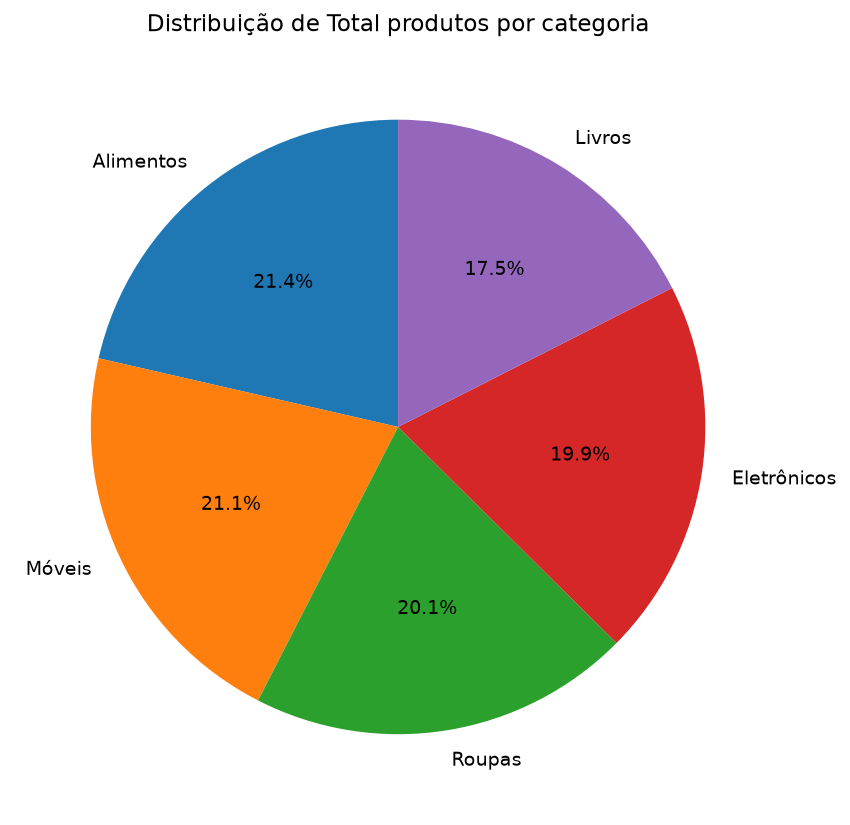

In [32]:
pergunta = "Mostre a distribuição de produtos por categoria em um gráfico de pizza"
process_question(pergunta)

In [33]:
pergunta = "qual é o produto mais caro e qual sua categoria?"
process_question(pergunta)

Query executada com sucesso. Resultados: 1 documentos.
Query MongoDB Gerada:
 {
    'collection': 'produtos',
    'aggregate': [
        {
            '$sort': {
                'preco': -1
            }
        },
        {
            '$limit': 1
        },
        {
            '$project': {
                'nome': 1,
                'categoria': 1,
                'preco': 1
            }
        }
    ]
}

Resultados da Query:
[
  {
    "_id": "6b0497a06e92ec7203312c55",
    "nome": "Tenetur",
    "preco": 998.83,
    "categoria": "Livros"
  }
]

Interpretação:
O produto mais caro encontrado na consulta é o 'Tenetur', que pertence à categoria 'Livros' e tem um preço de 998,83.
Nenhum gráfico gerado.


Query executada com sucesso. Resultados: 5 documentos.
Query MongoDB Gerada:
 {
    'collection': 'produtos',
    'aggregate': [
        {
            '$group': {
                '_id': '$categoria',
                'total_produtos': { '$sum': 1 }
            }
        }
    ]
}

Resultados da Query:
[
  {
    "_id": "Livros",
    "total_produtos": 149
  },
  {
    "_id": "Eletrônicos",
    "total_produtos": 169
  },
  {
    "_id": "Móveis",
    "total_produtos": 179
  },
  {
    "_id": "Roupas",
    "total_produtos": 171
  },
  {
    "_id": "Alimentos",
    "total_produtos": 182
  }
]

Interpretação:
A análise da quantidade de produtos por categoria revela que a categoria com o maior número de produtos é Alimentos, com 182 itens, seguida por Móveis com 179 produtos. Eletrônicos e Roupas têm quantidades semelhantes, com 169 e 171 produtos, respectivamente, enquanto a categoria de Livros possui a menor quantidade, com 149 produtos.



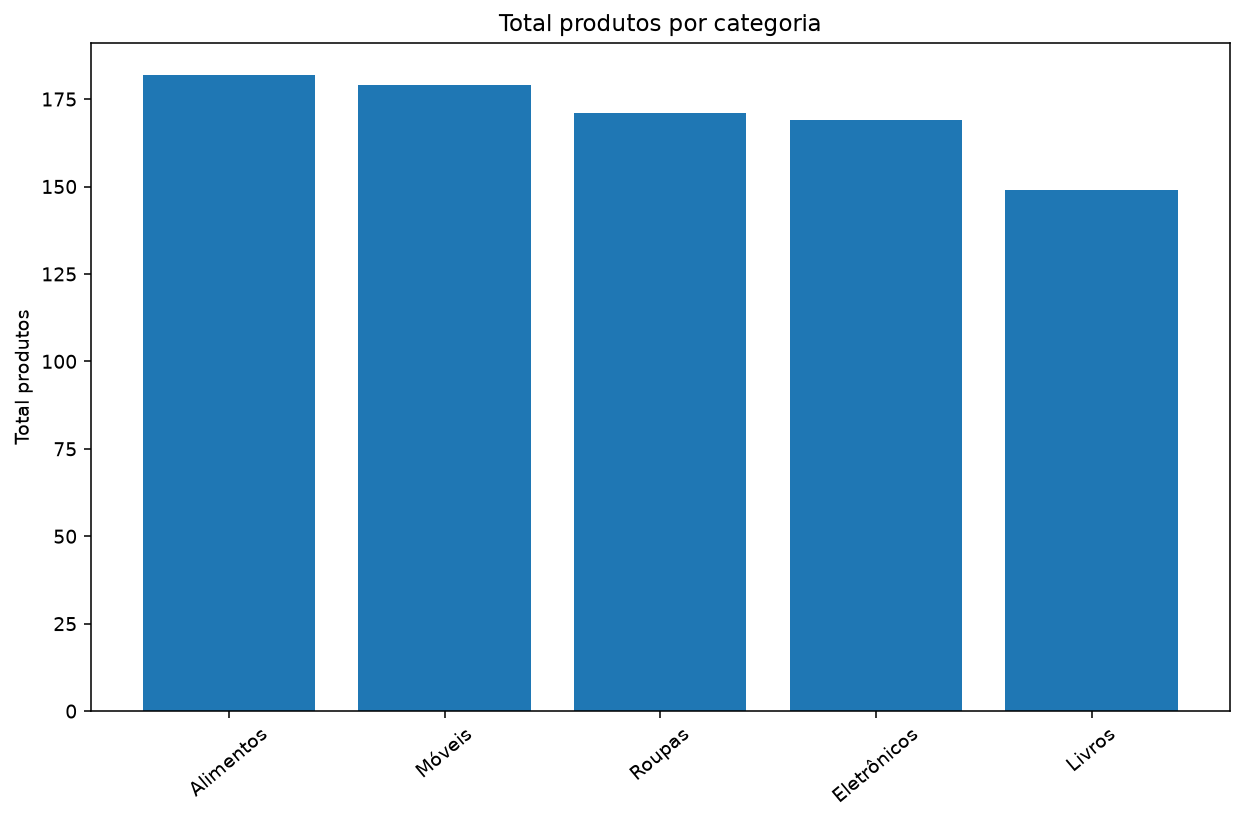

In [34]:
pergunta = "quantidade de produtos por categoria, faça um grafico barra"
process_question(pergunta)

Query executada com sucesso. Resultados: 5 documentos.
Query MongoDB Gerada:
 {
    'collection': 'produtos',
    'aggregate': [
        {
            '$group': {
                '_id': '$categoria',
                'total_produtos': { '$sum': 1 }
            }
        }
    ]
}

Resultados da Query:
[
  {
    "_id": "Livros",
    "total_produtos": 149
  },
  {
    "_id": "Roupas",
    "total_produtos": 171
  },
  {
    "_id": "Alimentos",
    "total_produtos": 182
  },
  {
    "_id": "Eletrônicos",
    "total_produtos": 169
  },
  {
    "_id": "Móveis",
    "total_produtos": 179
  }
]

Interpretação:
A distribuição de produtos por categoria mostra que a categoria com o maior número de produtos é Alimentos, com 182 itens, seguida por Roupas com 171, Eletrônicos com 169, Móveis com 179 e, por último, Livros com 149. Isso indica que a categoria de Alimentos é a mais representativa em termos de quantidade de produtos disponíveis.



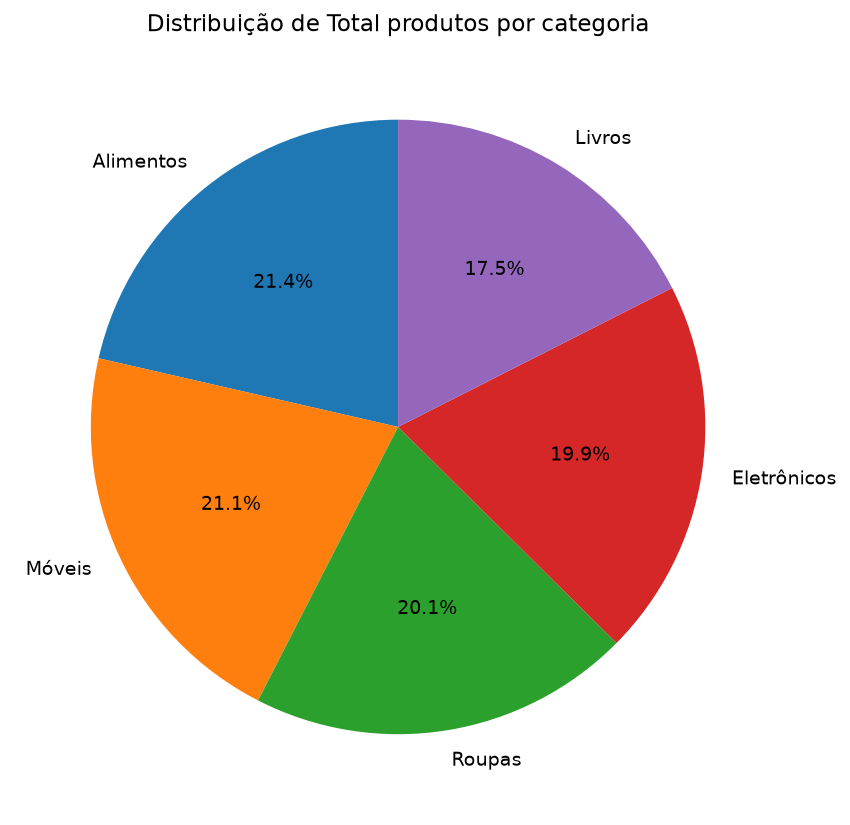

In [41]:

pergunta = "Mostre a distribuição de produtos por categoria em um gráfico de pizza"
process_question(pergunta)

Query executada com sucesso. Resultados: 5 documentos.
Query MongoDB Gerada:
 {
    'collection': 'pedidos',
    'aggregate': [
        {
            '$lookup': {
                'from': 'produtos',
                'localField': 'produto_id',
                'foreignField': '_id',
                'as': 'produto_info'
            }
        },
        {
            '$unwind': '$produto_info'
        },
        {
            '$group': {
                '_id': '$produto_info.categoria',
                'total_vendas': { '$sum': '$quantidade' }
            }
        }
    ]
}

Resultados da Query:
[
  {
    "_id": "Eletrônicos",
    "total_vendas": 1062
  },
  {
    "_id": "Móveis",
    "total_vendas": 972
  },
  {
    "_id": "Livros",
    "total_vendas": 866
  },
  {
    "_id": "Roupas",
    "total_vendas": 869
  },
  {
    "_id": "Alimentos",
    "total_vendas": 1025
  }
]

Interpretação:
As vendas estão distribuídas entre diferentes categorias, com 'Eletrônicos' liderando com 1062 vendas


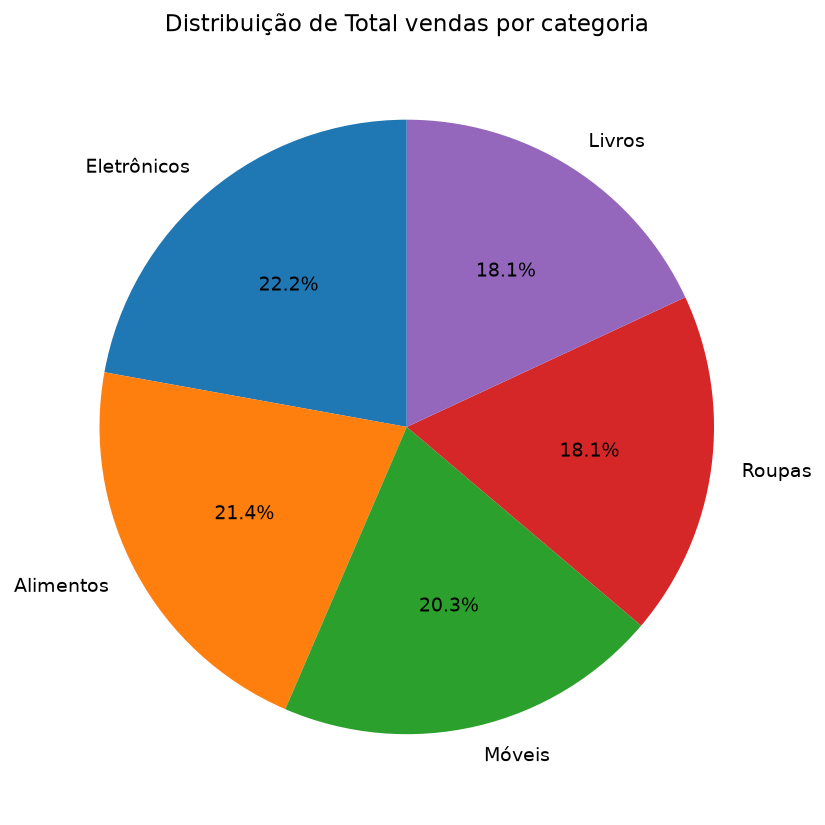

In [44]:
pergunta = "mostre a quantidade de vendas por categoria, num grafico pizza"
process_question(pergunta)

In [43]:
pergunta = "Quais as 5 primeiras linhas da colecao clientes?"
process_question(pergunta)

Query executada com sucesso. Resultados: 1300 documentos.
Query MongoDB Gerada:
 {
    'collection': 'clientes',
    'find': {},
    'limit': 5
}

Resultados da Query:
[
  {
    "_id": "6b0492d6423be53174015439",
    "nome": "Arthur Miguel Azevedo",
    "email": "enzo-gabrielramos@example.net",
    "endereco": "Estação Martins, 61\nSão Paulo\n52597-930 da Rocha / ES",
    "telefone": "+55 63 2081-4807"
  },
  {
    "_id": "6b0492d6423be5317401543a",
    "nome": "Lucca da Paz",
    "email": "sarahcamara@example.net",
    "endereco": "Área de Viana, 3\nGameleira\n53912921 Fernandes Grande / BA",
    "telefone": "+55 81 5595-1273"
  },
  {
    "_id": "6b0492d6423be5317401543b",
    "nome": "Caleb Leão",
    "email": "nascimentonatalia@example.org",
    "endereco": "Setor de Gomes, 90\nRio Branco\n83104-822 Pinto de Minas / SC",
    "telefone": "42 3572-4759"
  },
  {
    "_id": "6b0492d6423be5317401543c",
    "nome": "Rhavi Peixoto",
    "email": "maria-juliavargas@example.com",
    "ende